In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [2]:
#linear regression for multiple features

In [3]:
np.random.seed(0)
m=100
n=3
xraw = np.random.rand(m, n) *[1000,5,50]
xmean=np.mean(xraw , axis=0)
xstd=np.std(xraw , axis=0)
x=(xraw-xmean)/xstd

In [4]:
wtrue=np.array([2,-1.5,3])
btrue=5
y=(x@wtrue)+btrue+np.random.rand(m)
w=np.zeros(n)
b=0.0
alpha=0.01
maxiter=5000
cost=[]

In [5]:
for i in range(maxiter):
    yhat=x@w+b
    cost.append(1/(2*m)*np.sum((yhat-y)**2))
    dw=1/m*(x.T@(yhat-y))
    db=1/m*np.sum((yhat-y))
    w-=alpha*dw
    b-=alpha*db
    

In [6]:
print('target weights= ', wtrue)
print('learned weights= ', np.round(w,2))
print('target bias= ', btrue)
print(f'learned bias={b:.2f}')

target weights=  [ 2.  -1.5  3. ]
learned weights=  [ 1.98 -1.47  2.98]
target bias=  5
learned bias=5.47


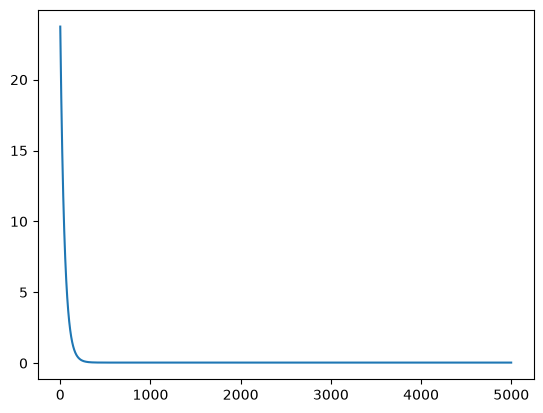

In [7]:
plt.plot(cost)

In [9]:
#logistic regression

In [10]:
from sklearn.datasets import make_blobs
xraw , y= make_blobs(n_samples=200,centers=2,n_features=2,random_state=42)

Training Accuracy: 100.00%


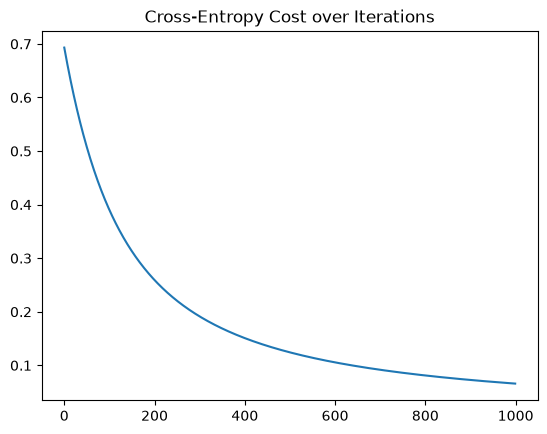

In [11]:
xmean=np.mean(xraw,axis=0)
xstd=np.std(xraw,axis=0)
X=(xraw-xmean)/xstd
def sigmoid(x):
    return 1/(1+np.exp(-x))
m,n=X.shape
w=np.zeros(n)
b=0.0
maxiter=1000
alpha=0.01
cost_history=[]
for i in range(maxiter):
    yhat=sigmoid(X@w+b)
    yhat=np.clip(yhat,1e-12,1-1e-12)
    cost = -np.mean(y * np.log(yhat) + (1 - y) * np.log(1 - yhat))
    cost_history.append(cost)
    dw = (X.T @ (yhat - y)) / m
    db = np.mean(yhat - y)
    w = w - alpha * dw
    b = b - alpha * db
final_probs = sigmoid(X @ w + b)
predictions = np.round(final_probs)

# Calculate how many predictions matched the true 'y' labels
accuracy = np.mean(predictions == y) * 100
print(f"Training Accuracy: {accuracy:.2f}%")

# Plot the cost curve to ensure it went down
plt.plot(cost_history)
plt.title("Cross-Entropy Cost over Iterations")
plt.show()    

Final Weights: [ 0.31908149 -0.44169458]
Final Bias: 0.0003


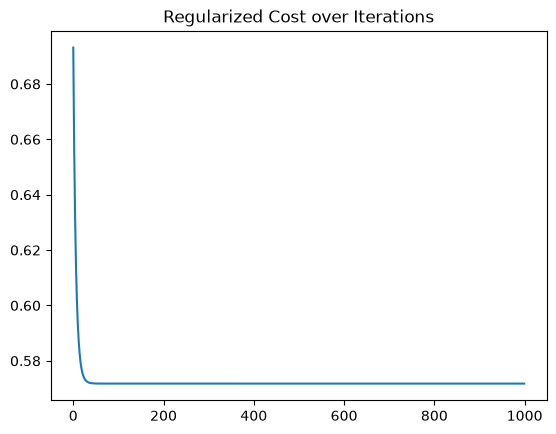

In [12]:

from sklearn.datasets import make_moons

# 1. GENERATE COMPLEX DATA
# We use make_moons instead of make_blobs. It creates overlapping, crescent-shaped 
# data that is highly prone to overfitting if you add polynomial features.
X_raw, y = make_moons(n_samples=200, noise=0.2, random_state=42)

# Scale features
X_mean = np.mean(X_raw, axis=0)
X_std = np.std(X_raw, axis=0)
X = (X_raw - X_mean) / X_std

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# 2. INITIALIZE VARIABLES (Added lambda_)
m, n = X.shape
w = np.zeros(n)
b = 0.0
alpha = 0.1
lambda_ = 100  # The regularization penalty knob (try changing this to 0, 1, or 100)
iterations = 1000
cost_history = []

# 3. REGULARIZED LOOP
for i in range(iterations):
    # Predict
    y_hat = sigmoid(X @ w + b)
    y_hat = np.clip(y_hat, 1e-12, 1 - 1e-12)
    
    # Calculate Cost (WITH REGULARIZATION PENALTY)
    # Note: np.sum(w**2) squares every weight and adds them all together
    cross_entropy_cost = -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))
    reg_penalty = (lambda_ / (2 * m)) * np.sum(w ** 2)
    
    cost = cross_entropy_cost + reg_penalty
    cost_history.append(cost)
    
    # Calculate Gradients (WITH REGULARIZATION TERM)
    # We add (lambda_ / m) * w to the old dw formula. 
    dw = (X.T @ (y_hat - y)) / m + (lambda_ / m) * w
    db = np.mean(y_hat - y)  # Bias is never regularized!
    
    # Update
    w = w - alpha * dw
    b = b - alpha * db

print(f"Final Weights: {w}")
print(f"Final Bias: {b:.4f}")

plt.plot(cost_history)
plt.title("Regularized Cost over Iterations")
plt.show()